# Multilayer Perceptrons — Group Assignment
**Members:** Senay Teweldebrhan, Ricardo, Juan, and Zeyneb  
**Scope:** Challenges 1 and 2 from `MultiLayerPerceptrons_Workshop.ipynb`.

This notebook compares three MNIST implementations, then derives and trains a NumPy network from scratch. Run cells in order. Numbers are generated by execution; the original workshop's example timing table is not reused.

## Learning objectives and navigation
1. Shared data preparation and controlled framework comparison.
2. Hyperparameter experiments, comparison table, and discussion answers.
3. NumPy forward/backward propagation, gradient check, training, and experiments.
4. Activation/gradient visualizations and a 150–200-word reflection.

The input layer is not counted as a trainable layer: two hidden layers plus one output layer form the required three-layer network.


## Execution status
Challenge 2 and the shared setup have been executed and their outputs are embedded below. Challenge 1 code has been syntax-checked but **not executed in this environment**: TensorFlow and PyTorch are unavailable and dependency installation could not resolve TensorFlow. Run all cells in a configured environment to generate the MNIST comparison and hyperparameter results. No unmeasured framework timings or accuracies are presented as results.


In [2]:
# If imports fail, uncomment this line, run it once, and restart the kernel.
# %pip install numpy pandas matplotlib scikit-learn tensorflow-cpu torch
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'  # Consistent CPU comparison
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['OMP_NUM_THREADS'] = '2'
import time, random, platform, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons
OUTPUT = Path('results'); OUTPUT.mkdir(exist_ok=True)
SEED = 42
np.random.seed(SEED); random.seed(SEED)
print('Python:', platform.python_version(), '| Platform:', platform.platform())


Python: 3.12.10 | Platform: Windows-11-10.0.26100-SP0


## Challenge 1 — MNIST framework comparison
MNIST contains 28 × 28 grayscale images of digits 0–9. Each image becomes a 784-element vector. Pixel intensities are divided by 255 in **all** implementations. A fixed stratified split creates 54,000 training and 6,000 validation examples; the official 10,000 test images remain separate.

The baseline is **784 → 128 ReLU → 64 ReLU → 10**, Adam, learning rate 0.001, batch size 64, and 5 epochs. All models receive identical initial weights and epoch-wise batch order. All use the same validation data every epoch. Keras returns softmax probabilities; the other implementations return logits with the corresponding loss setting. These represent the same classification objective.

Timing includes training and epoch validation, including first-call tracing, but excludes download, model construction, and final test evaluation. CPU thread limits are matched. This measures these implementations on this machine, not an intrinsic ranking of frameworks. A single run does not establish statistical superiority. TensorFlow Core here follows the workshop: Keras layers with a custom TensorFlow training loop.


TensorFlow: 2.21.0 | Keras: 3.15.1 | PyTorch: 2.15.0+cpu
Device: CPU; threads: 2. First run includes tracing overhead.
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Train / validation / test: (54000, 784) (6000, 784) (10000, 784)


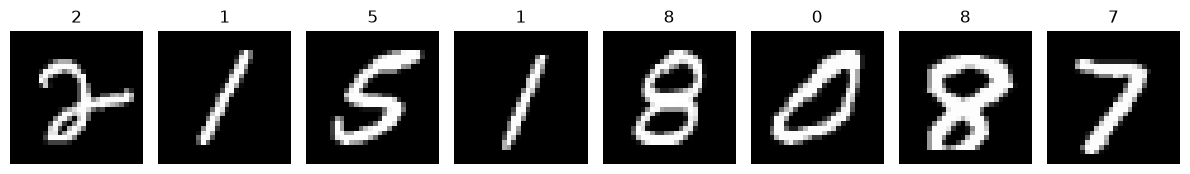

In [3]:
import tensorflow as tf
from tensorflow import keras
import torch
from torch import nn
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
torch.set_num_threads(2)
print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__, '| PyTorch:', torch.__version__)
print('Device: CPU; threads: 2. First run includes tracing overhead.')
(raw_x, raw_y), (raw_test, y_test) = keras.datasets.mnist.load_data()
X_all = raw_x.reshape(-1,784).astype('float32') / 255
X_test = raw_test.reshape(-1,784).astype('float32') / 255
X_train, X_val, y_train, y_val = train_test_split(
    X_all, raw_y, test_size=0.1, stratify=raw_y, random_state=SEED)
y_train, y_val, y_test = [a.astype('int64') for a in (y_train,y_val,y_test)]
print('Train / validation / test:', X_train.shape, X_val.shape, X_test.shape)
fig, axes = plt.subplots(1,8,figsize=(12,2))
for i,ax in enumerate(axes):
    ax.imshow(X_train[i].reshape(28,28),cmap='gray'); ax.set_title(str(y_train[i])); ax.axis('off')
plt.tight_layout(); plt.show()


### Model construction and shared experimental controls
A dense layer has `(inputs × outputs) + outputs` trainable parameters. The baseline has 100,480 + 8,256 + 650 = **109,386 parameters**. He initialization is used for ReLU hidden layers, with a Glorot-style output initialization. Adam epsilon is explicitly matched, although numerical implementations can still differ.


In [4]:
class TorchMLP(nn.Module):
    def __init__(self, widths):
        super().__init__()
        self.layers = nn.ModuleList([nn.Linear(a,b) for a,b in zip(widths[:-1],widths[1:])])
    def forward(self, images):
        for layer in self.layers[:-1]: images = torch.relu(layer(images))
        return self.layers[-1](images)  # logits; no softmax before CrossEntropyLoss

def initial_weights(widths, seed):
    rng = np.random.default_rng(seed)
    pairs = []
    for i,(a,b) in enumerate(zip(widths[:-1],widths[1:])):
        scale = np.sqrt(2/a) if i < len(widths)-2 else np.sqrt(2/(a+b))
        pairs.append((rng.normal(0,scale,(a,b)).astype('float32'),np.zeros(b,'float32')))
    return pairs

def make_tf_model(widths, pairs, probabilities=False):
    model = keras.Sequential([keras.layers.Input(shape=(widths[0],))] +
        [keras.layers.Dense(w,activation='relu') for w in widths[1:-1]] +
        [keras.layers.Dense(widths[-1],activation='softmax' if probabilities else None)])
    model.set_weights([v for pair in pairs for v in pair])
    return model

def tf_dataset(x,y,batch):
    ds=tf.data.Dataset.from_tensor_slices((x,y)).batch(batch)
    options=tf.data.Options(); options.threading.private_threadpool_size=2
    return ds.with_options(options)

def score_tf(model,x,y,batch,logits):
    loss_fn=keras.losses.SparseCategoricalCrossentropy(from_logits=logits,reduction='none')
    total_loss=0.; correct=0
    for xb,yb in tf_dataset(x,y,batch):
        pred=model(xb,training=False)
        total_loss += float(tf.reduce_sum(loss_fn(yb,pred)))
        correct += int(tf.reduce_sum(tf.cast(tf.argmax(pred,axis=1)==yb,tf.int32)))
    return total_loss/len(y),correct/len(y)

def score_torch(model,x,y,batch):
    model.eval(); total_loss=0.; correct=0
    with torch.no_grad():
        for start in range(0,len(y),batch):
            images=torch.from_numpy(x[start:start+batch]); labels=torch.from_numpy(y[start:start+batch])
            pred=model(images)
            total_loss+=nn.functional.cross_entropy(pred,labels,reduction='sum').item()
            correct+=(pred.argmax(1)==labels).sum().item()
    return total_loss/len(y),correct/len(y)


### Training in the three implementations
The Keras branch delegates gradient computation and updates to `fit`. The PyTorch branch explicitly resets gradients, predicts, computes loss, backpropagates, and updates weights. TensorFlow Core records operations with `GradientTape` and applies their gradients explicitly. Every new experiment rebuilds the model and optimizer.


In [5]:
def run_framework(framework, config, evaluate_test=False):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED); torch.manual_seed(SEED)
    widths=[784,*config.get('hidden',(128,64)),10]
    pairs=initial_weights(widths,SEED)
    batch=config['batch']; lr=config['lr']; epochs=config['epochs']
    if framework=='PyTorch':
        model=TorchMLP(widths)
        with torch.no_grad():
            for layer,(w,b) in zip(model.layers,pairs):
                layer.weight.copy_(torch.from_numpy(w.T)); layer.bias.copy_(torch.from_numpy(b))
        criterion=nn.CrossEntropyLoss()
        optimizer=torch.optim.Adam(model.parameters(),lr=lr,eps=1e-7)
    else:
        model=make_tf_model(widths,pairs,probabilities=framework=='Keras')
        optimizer_tf=keras.optimizers.Adam(learning_rate=lr,epsilon=1e-7)
        loss_object=keras.losses.SparseCategoricalCrossentropy(from_logits=framework!='Keras')
        if framework=='Keras':
            model.compile(optimizer=optimizer_tf,loss=loss_object,metrics=['accuracy'],jit_compile=False)
        else:
            @tf.function(reduce_retracing=True)
            def train_step(images,labels):
                with tf.GradientTape() as tape:
                    predictions=model(images,training=True)
                    loss=loss_object(labels,predictions)
                gradients=tape.gradient(loss,model.trainable_variables)
                optimizer_tf.apply_gradients(zip(gradients,model.trainable_variables))
                return loss,tf.reduce_sum(tf.cast(tf.argmax(predictions,axis=1)==labels,tf.int32))
    history=[]
    started=time.perf_counter()
    for epoch in range(epochs):
        order=np.random.default_rng(SEED+epoch).permutation(len(y_train))
        xe,ye=X_train[order],y_train[order]
        if framework=='Keras':
            h=model.fit(tf_dataset(xe,ye,batch),validation_data=tf_dataset(X_val,y_val,batch),
                        epochs=1,verbose=0).history
            row={k:float(h[k][0]) for k in ('loss','accuracy','val_loss','val_accuracy')}
        else:
            running=0.; correct=0
            if framework=='PyTorch': model.train()
            for start in range(0,len(ye),batch):
                xb,yb=xe[start:start+batch],ye[start:start+batch]
                if framework=='PyTorch':
                    images=torch.from_numpy(xb); labels=torch.from_numpy(yb)
                    optimizer.zero_grad(); predictions=model(images)
                    loss=criterion(predictions,labels); loss.backward(); optimizer.step()
                    running+=loss.item()*len(yb)
                    correct+=(predictions.argmax(1)==labels).sum().item()
                else:
                    loss,n_correct=train_step(tf.convert_to_tensor(xb),tf.convert_to_tensor(yb))
                    running+=float(loss)*len(yb); correct+=int(n_correct)
            vl,va=(score_torch(model,X_val,y_val,batch) if framework=='PyTorch'
                   else score_tf(model,X_val,y_val,batch,True))
            row=dict(loss=running/len(ye),accuracy=correct/len(ye),val_loss=vl,val_accuracy=va)
        history.append(row)
    seconds=time.perf_counter()-started
    result=dict(framework=framework,experiment=config['name'],epochs=epochs,batch=batch,lr=lr,
                hidden=str(widths[1:-1]),seconds=seconds,seconds_per_epoch=seconds/epochs,
                val_accuracy=history[-1]['val_accuracy'],val_loss=history[-1]['val_loss'])
    if evaluate_test:
        tl,ta=(score_torch(model,X_test,y_test,batch) if framework=='PyTorch'
               else score_tf(model,X_test,y_test,batch,framework!='Keras'))
        result.update(test_loss=tl,test_accuracy=ta)
    print(framework,config['name'],f'{seconds:.2f}s; validation accuracy {result["val_accuracy"]:.4f}')
    return result,pd.DataFrame(history)

baseline=dict(name='baseline',batch=64,lr=0.001,epochs=5,hidden=(128,64))
frameworks=['Keras','PyTorch','TensorFlow Core']
baseline_rows=[]; histories={}
for framework in frameworks:
    row,hist=run_framework(framework,baseline,evaluate_test=True)
    baseline_rows.append(row); histories[framework]=hist
baseline_results=pd.DataFrame(baseline_rows)
display(baseline_results.round(4))
baseline_results.to_csv(OUTPUT/'challenge1_baseline.csv',index=False)


c:\Users\Senay\Documents\Machine Learning Frameworks\New folder\multilayer-perceptron\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Keras baseline 17.39s; validation accuracy 0.9732
PyTorch baseline 10.42s; validation accuracy 0.9715
TensorFlow Core baseline 12.17s; validation accuracy 0.9732


,framework,experiment,epochs,batch,lr,hidden,seconds,seconds_per_epoch,val_accuracy,val_loss,test_loss,test_accuracy
0,Keras,baseline,5,64,0.001,"[128, 64]",17.3941,3.4788,0.9732,0.0939,0.0842,0.9748
1,PyTorch,baseline,5,64,0.001,"[128, 64]",10.4158,2.0832,0.9715,0.0932,0.0791,0.9752
2,TensorFlow Core,baseline,5,64,0.001,"[128, 64]",12.1719,2.4344,0.9732,0.0939,0.0842,0.9748


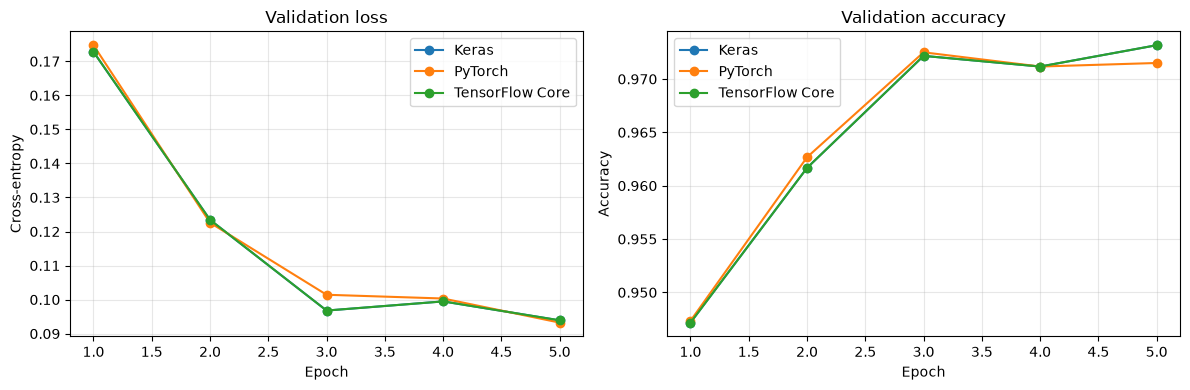

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,h in histories.items():
    axes[0].plot(np.arange(1,len(h)+1),h.val_loss,marker='o',label=name)
    axes[1].plot(np.arange(1,len(h)+1),h.val_accuracy,marker='o',label=name)
axes[0].set(title='Validation loss',xlabel='Epoch',ylabel='Cross-entropy')
axes[1].set(title='Validation accuracy',xlabel='Epoch',ylabel='Accuracy')
for ax in axes: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUTPUT/'challenge1_validation.png',dpi=160); plt.show()


### Hyperparameter experiments
Change one setting at a time relative to the baseline: batch size 128, learning rate 0.01, or 10 epochs. Run every configuration in every implementation. Use validation results for these comparisons; do not tune against the test set. More epochs naturally increase total time, so report seconds per epoch too. These are controlled demonstrations, not an exhaustive search.


In [7]:
experiment_rows=[]
configs=[dict(baseline,name='batch_128',batch=128),
         dict(baseline,name='learning_rate_0.01',lr=0.01),
         dict(baseline,name='epochs_10',epochs=10)]
for config in configs:
    for framework in frameworks:
        row,_=run_framework(framework,config)
        experiment_rows.append(row)
experiments=pd.concat([baseline_results.drop(columns=['test_accuracy','test_loss']),
                       pd.DataFrame(experiment_rows)],ignore_index=True)
display(experiments.round(4))
experiments.to_csv(OUTPUT/'challenge1_experiments.csv',index=False)
for framework in frameworks:
    subset=experiments[experiments.framework==framework]
    base=subset[subset.experiment=='baseline'].iloc[0]
    for _,row in subset[subset.experiment!='baseline'].iterrows():
        print(f'{framework}, {row.experiment}: time ratio {row.seconds/base.seconds:.2f}; '
              f'validation accuracy change {(row.val_accuracy-base.val_accuracy)*100:+.2f} percentage points.')


c:\Users\Senay\Documents\Machine Learning Frameworks\New folder\multilayer-perceptron\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Keras batch_128 10.44s; validation accuracy 0.9717
PyTorch batch_128 6.20s; validation accuracy 0.9735
TensorFlow Core batch_128 9.32s; validation accuracy 0.9717
Keras learning_rate_0.01 14.82s; validation accuracy 0.9625
PyTorch learning_rate_0.01 11.01s; validation accuracy 0.9647
TensorFlow Core learning_rate_0.01 12.05s; validation accuracy 0.9625
Keras epochs_10 26.14s; validation accuracy 0.9772
PyTorch epochs_10 19.43s; validation accuracy 0.9752
TensorFlow Core epochs_10 23.02s; validation accuracy 0.9772


,framework,experiment,epochs,batch,lr,hidden,seconds,seconds_per_epoch,val_accuracy,val_loss
0,Keras,baseline,5,64,0.001,"[128, 64]",17.3941,3.4788,0.9732,0.0939
1,PyTorch,baseline,5,64,0.001,"[128, 64]",10.4158,2.0832,0.9715,0.0932
2,TensorFlow Core,baseline,5,64,0.001,"[128, 64]",12.1719,2.4344,0.9732,0.0939
3,Keras,batch_128,5,128,0.001,"[128, 64]",10.4404,2.0881,0.9717,0.0944
4,PyTorch,batch_128,5,128,0.001,"[128, 64]",6.2008,1.2402,0.9735,0.0898
5,TensorFlow Core,batch_128,5,128,0.001,"[128, 64]",9.3186,1.8637,0.9717,0.0944
6,Keras,learning_rate_0.01,5,64,0.010,"[128, 64]",14.8167,2.9633,0.9625,0.1554
7,PyTorch,learning_rate_0.01,5,64,0.010,"[128, 64]",11.0143,2.2029,0.9647,0.1481
8,TensorFlow Core,learning_rate_0.01,5,64,0.010,"[128, 64]",12.0494,2.4099,0.9625,0.1554
9,Keras,epochs_10,10,64,0.001,"[128, 64]",26.1352,2.6135,0.9772,0.0937


Keras, batch_128: time ratio 0.60; validation accuracy change -0.15 percentage points.
Keras, learning_rate_0.01: time ratio 0.85; validation accuracy change -1.07 percentage points.
Keras, epochs_10: time ratio 1.50; validation accuracy change +0.40 percentage points.
PyTorch, batch_128: time ratio 0.60; validation accuracy change +0.20 percentage points.
PyTorch, learning_rate_0.01: time ratio 1.06; validation accuracy change -0.68 percentage points.
PyTorch, epochs_10: time ratio 1.87; validation accuracy change +0.37 percentage points.
TensorFlow Core, batch_128: time ratio 0.77; validation accuracy change -0.15 percentage points.
TensorFlow Core, learning_rate_0.01: time ratio 0.99; validation accuracy change -1.07 percentage points.
TensorFlow Core, epochs_10: time ratio 1.89; validation accuracy change +0.40 percentage points.


### Answers to the workshop questions
**Keras:** `val_accuracy` is the fraction of correct predictions on the held-out validation set after an epoch. `val_loss` is the validation cross-entropy, which also reflects confidence. Validation examples do not update weights. Falling training loss alongside rising validation loss can indicate overfitting.

**PyTorch:** `images` contains a batch of flattened image features; `labels` contains their integer digit targets. `criterion` is the cross-entropy loss function. `optimizer` is Adam, which updates parameters from gradients. `zero_grad()` clears accumulated gradients; `backward()` computes them; `step()` applies the update. `eval()` selects evaluation behavior, and `no_grad()` disables gradient tracking.

**TensorFlow:** `@tf.function` traces TensorFlow operations into a reusable graph; tracing costs time initially and speed gains depend on the workload. `loss_object` computes sparse categorical cross-entropy from integer labels and raw logits. `optimizer_tf` applies Adam updates to trainable variables using gradients recorded by `GradientTape`.

**Output interpretation:** Softmax maps ten logits into probabilities summing to one. PyTorch `CrossEntropyLoss` already incorporates the necessary log-softmax operation; TensorFlow uses `from_logits=True`. Applying softmax first in these branches would change the intended computation.


In [8]:
pros={'Keras':'Concise fit API; built-in validation and metric tracking',
      'PyTorch':'Explicit, easy-to-inspect training and gradient updates',
      'TensorFlow Core':'Custom training with GradientTape and graph execution'}
cons={'Keras':'Less explicit training mechanics in the standard fit interface',
      'PyTorch':'Requires manual loop, metrics, and evaluation handling',
      'TensorFlow Core':'More code; graph tracing requires care'}
comparison=baseline_results[['framework','seconds','test_accuracy']].copy()
comparison.columns=['Framework','Speed (seconds)','Test accuracy']
comparison['Pros']=comparison.Framework.map(pros); comparison['Cons']=comparison.Framework.map(cons)
display(comparison); comparison.to_csv(OUTPUT/'challenge1_comparison.csv',index=False)
fastest=baseline_results.loc[baseline_results.seconds.idxmin()]
highest=baseline_results.loc[baseline_results.test_accuracy.idxmax()]
display(Markdown(f'**Measured summary:** {fastest.framework} had the shortest measured training-plus-validation '
                 f'time ({fastest.seconds:.2f} s). {highest.framework} had the highest baseline test accuracy '
                 f'({highest.test_accuracy:.2%}). These are single-run observations.'))


,Framework,Speed (seconds),Test accuracy,Pros,Cons
0,Keras,17.394110,0.9748,Concise fit API; built-in validation and metri...,Less explicit training mechanics in the standa...
1,PyTorch,10.415827,0.9752,"Explicit, easy-to-inspect training and gradien...","Requires manual loop, metrics, and evaluation ..."
2,TensorFlow Core,12.171894,0.9748,Custom training with GradientTape and graph ex...,More code; graph tracing requires care


**Measured summary:** PyTorch had the shortest measured training-plus-validation time (10.42 s). PyTorch had the highest baseline test accuracy (97.52%). These are single-run observations.

### Talking points: preferred implementation
For this standard MNIST task, our proposed preference is **Keras** because its concise training interface makes the model and validation process easy to communicate. This is a usability argument, not an assumption that Keras always wins on speed or accuracy. Discuss the measured table above alongside this preference.

PyTorch is attractive when we want to inspect each training step or change the learning algorithm. TensorFlow's custom loop is useful when we want explicit gradient control within TensorFlow. All three approaches can support complex models and large datasets; “beginner-friendly” does not mean “only for beginners.” Keras and TensorFlow are not entirely independent systems here, since Keras uses TensorFlow as its backend.

The original workshop used different input ranges and different training-set sizes across branches. This notebook corrects both. Remaining limitations include one seed, different low-level kernels and optimizer implementations, sequential timing, and Python versus graph overhead. Repeat on the same hardware with several seeds before claiming a reliable ranking.


## Challenge 2 — An MLP from scratch using NumPy
We use a noisy two-moons binary classification dataset because its nonlinear boundary makes learning visible. This is permitted by the challenge; the required MNIST comparison remains in Challenge 1. The baseline is **2 → 16 → 8 → 1**, with two ReLU hidden layers and a sigmoid output. We use a stratified train/validation/test split and fit feature scaling only on training data.

### Forward propagation and the loss
Rows represent samples (the transpose convention of the worksheet):
\[
Z^{[l]}=A^{[l-1]}W^{[l]}+b^{[l]},\qquad A^{[l]}=g(Z^{[l]}).
\]
For a batch of size \(m\), \(A^{[l-1]}\) has shape \((m,n_{l-1})\), \(W^{[l]}\) has shape \((n_{l-1},n_l)\), and \(b^{[l]}\) has shape \((1,n_l)\).

Binary cross-entropy is evaluated stably from output logits:
\[
L=\frac1m\sum_i[\log(1+e^{z_i})-y_i z_i].
\]
This is a loss, not simply the signed residual \(y-\hat y\).

### Backpropagation derivation
For sigmoid output combined with binary cross-entropy:
\[
dZ^{[L]}=(\hat Y-Y)/m,\quad
dW^{[l]}=(A^{[l-1]})^T dZ^{[l]},\quad
db^{[l]}=\sum_{i=1}^{m}dZ_i^{[l]}.
\]
The chain rule propagates the gradient through earlier layers:
\[
dA^{[l-1]}=dZ^{[l]}(W^{[l]})^T,\quad
dZ^{[l-1]}=dA^{[l-1]}\odot g'(Z^{[l-1]}).
\]
ReLU has derivative 1 for positive inputs and 0 for negative inputs (we use 0 at zero). Sigmoid has derivative \(a(1-a)\). Gradients are computed for all layers before any updates:
\[
W\leftarrow W-\alpha dW,\qquad b\leftarrow b-\alpha db.
\]
The averaging factor is included once, in output `dZ`. No framework layers or automatic differentiation are used below.


In [9]:
mx,my=make_moons(n_samples=1000,noise=.20,random_state=SEED)
mx_train,mx_hold,my_train,my_hold=train_test_split(mx,my,test_size=.4,stratify=my,random_state=SEED)
mx_val,mx_test,my_val,my_test=train_test_split(mx_hold,my_hold,test_size=.5,stratify=my_hold,random_state=SEED)
scaler=StandardScaler().fit(mx_train)
mx_train,mx_val,mx_test=[scaler.transform(x) for x in (mx_train,mx_val,mx_test)]
my_train,my_val,my_test=[y.reshape(-1,1) for y in (my_train,my_val,my_test)]
print('Train / validation / test:',len(my_train),len(my_val),len(my_test))

class NumPyMLP:
    def __init__(self,widths,activation='relu',initialization='auto',seed=42):
        self.widths=widths; self.activation=activation
        rng=np.random.default_rng(seed); self.W=[]; self.b=[]
        for i,(a,b) in enumerate(zip(widths[:-1],widths[1:])):
            scale=np.sqrt(2/a) if activation=='relu' and i<len(widths)-2 else np.sqrt(1/a)
            if initialization=='tiny': scale=.01
            if initialization=='large': scale=3.
            self.W.append(rng.normal(0,scale,(a,b))); self.b.append(np.zeros((1,b)))
    @staticmethod
    def sigmoid(z):
        # Stable sigmoid without exponential overflow.
        return np.exp(-np.logaddexp(0,-z))
    def forward(self,X):
        A=[X]; Z=[]
        for i,(w,b) in enumerate(zip(self.W,self.b)):
            z=A[-1]@w+b; Z.append(z)
            a=(self.sigmoid(z) if i==len(self.W)-1 or self.activation=='sigmoid' else np.maximum(0,z))
            A.append(a)
        return A,Z
    def loss(self,X,y):
        _,Z=self.forward(X)
        return float(np.mean(np.logaddexp(0,Z[-1])-y*Z[-1]))
    def backward(self,A,Z,y):
        dZ=(A[-1]-y)/len(y); dWs=[None]*len(self.W); dbs=[None]*len(self.W); dZs=[None]*len(self.W)
        for i in range(len(self.W)-1,-1,-1):
            dZs[i]=dZ.copy(); dWs[i]=A[i].T@dZ; dbs[i]=dZ.sum(axis=0,keepdims=True)
            if i>0:
                dA=dZ@self.W[i].T
                derivative=(Z[i-1]>0) if self.activation=='relu' else A[i]*(1-A[i])
                dZ=dA*derivative
        return dWs,dbs,dZs
    def predict(self,X): return (self.forward(X)[0][-1]>=.5).astype(int)
    def fit(self,X,y,Xv,yv,lr=.1,epochs=1500):
        history=[]
        for epoch in range(epochs+1):
            A,Z=self.forward(X); dw,db,dz=self.backward(A,Z,y)
            loss=float(np.mean(np.logaddexp(0,Z[-1])-y*Z[-1]))
            if not np.isfinite(loss): raise FloatingPointError('Non-finite loss; reduce learning rate/initialization.')
            history.append([epoch,loss,self.loss(Xv,yv),*[float(np.linalg.norm(g)) for g in dw]])
            if epoch<epochs:
                for i in range(len(self.W)):
                    self.W[i]-=lr*dw[i]; self.b[i]-=lr*db[i]
        return pd.DataFrame(history,columns=['epoch','train_loss','val_loss']+[f'grad_W{i+1}' for i in range(len(self.W))])


Train / validation / test: 600 200 200


### Verify the analytical gradients
Central finite differences approximate each derivative by changing a parameter slightly in both directions. We check all weights and biases of a small sigmoid network, avoiding ReLU's nondifferentiable zero. This independently checks the chain rule implementation before training.


In [10]:
check_model=NumPyMLP([2,3,2,1],activation='sigmoid',seed=7)
cx=mx_train[:5]; cy=my_train[:5]
A,Z=check_model.forward(cx); dws,dbs,_=check_model.backward(A,Z,cy)
errors=[]; eps=1e-5
for parameter,analytical in zip(check_model.W+check_model.b,dws+dbs):
    numerical=np.zeros_like(parameter)
    for index in np.ndindex(parameter.shape):
        old=parameter[index]
        parameter[index]=old+eps; plus=check_model.loss(cx,cy)
        parameter[index]=old-eps; minus=check_model.loss(cx,cy)
        parameter[index]=old
        numerical[index]=(plus-minus)/(2*eps)
    errors.append(np.max(np.abs(numerical-analytical)))
print('Maximum absolute gradient error:',max(errors))
assert max(errors)<1e-7, 'Gradient verification failed'


Maximum absolute gradient error: 8.345664437303668e-12


In [11]:
numpy_configs=[
    dict(name='baseline_relu',widths=[2,16,8,1],activation='relu',lr=.1),
    dict(name='sigmoid',widths=[2,16,8,1],activation='sigmoid',lr=.1),
    dict(name='lr_0.01',widths=[2,16,8,1],activation='relu',lr=.01),
    dict(name='lr_1.0',widths=[2,16,8,1],activation='relu',lr=1.),
    dict(name='third_hidden_relu',widths=[2,16,8,8,1],activation='relu',lr=.1),
    dict(name='third_hidden_sigmoid',widths=[2,16,8,8,1],activation='sigmoid',lr=.1),
    dict(name='tiny_initialization',widths=[2,16,8,1],activation='relu',lr=.1,initialization='tiny'),
    dict(name='large_initialization',widths=[2,16,8,1],activation='relu',lr=.1,initialization='large')]
numpy_models={}; numpy_histories={}; numpy_rows=[]
for config in numpy_configs:
    model=NumPyMLP(config['widths'],config['activation'],config.get('initialization','auto'),SEED)
    history=model.fit(mx_train,my_train,mx_val,my_val,lr=config['lr'])
    name=config['name']; numpy_models[name]=model; numpy_histories[name]=history
    numpy_rows.append(dict(experiment=name,initial_loss=history.train_loss.iloc[0],
        final_train_loss=history.train_loss.iloc[-1],val_loss=history.val_loss.iloc[-1],
        val_accuracy=np.mean(model.predict(mx_val)==my_val)))
numpy_results=pd.DataFrame(numpy_rows)
display(numpy_results.round(5)); numpy_results.to_csv(OUTPUT/'challenge2_experiments.csv',index=False)
selected_name=numpy_results.sort_values('val_loss').iloc[0].experiment
selected=numpy_models[selected_name]
test_accuracy=float(np.mean(selected.predict(mx_test)==my_test))
print(f'Selected by validation loss: {selected_name}; held-out test accuracy: {test_accuracy:.2%}')


,experiment,initial_loss,final_train_loss,val_loss,val_accuracy
0,baseline_relu,0.73489,0.06679,0.08723,0.980
1,sigmoid,0.69078,0.30329,0.30012,0.870
2,lr_0.01,0.73489,0.23823,0.23625,0.900
3,lr_1.0,0.73489,0.05141,0.10606,0.975
4,third_hidden_relu,0.76257,0.05518,0.07891,0.980
5,third_hidden_sigmoid,0.69974,0.31694,0.31399,0.865
6,tiny_initialization,0.69315,0.69207,0.69212,0.770
7,large_initialization,25.67878,0.04479,0.12670,0.975


Selected by validation loss: third_hidden_relu; held-out test accuracy: 97.00%


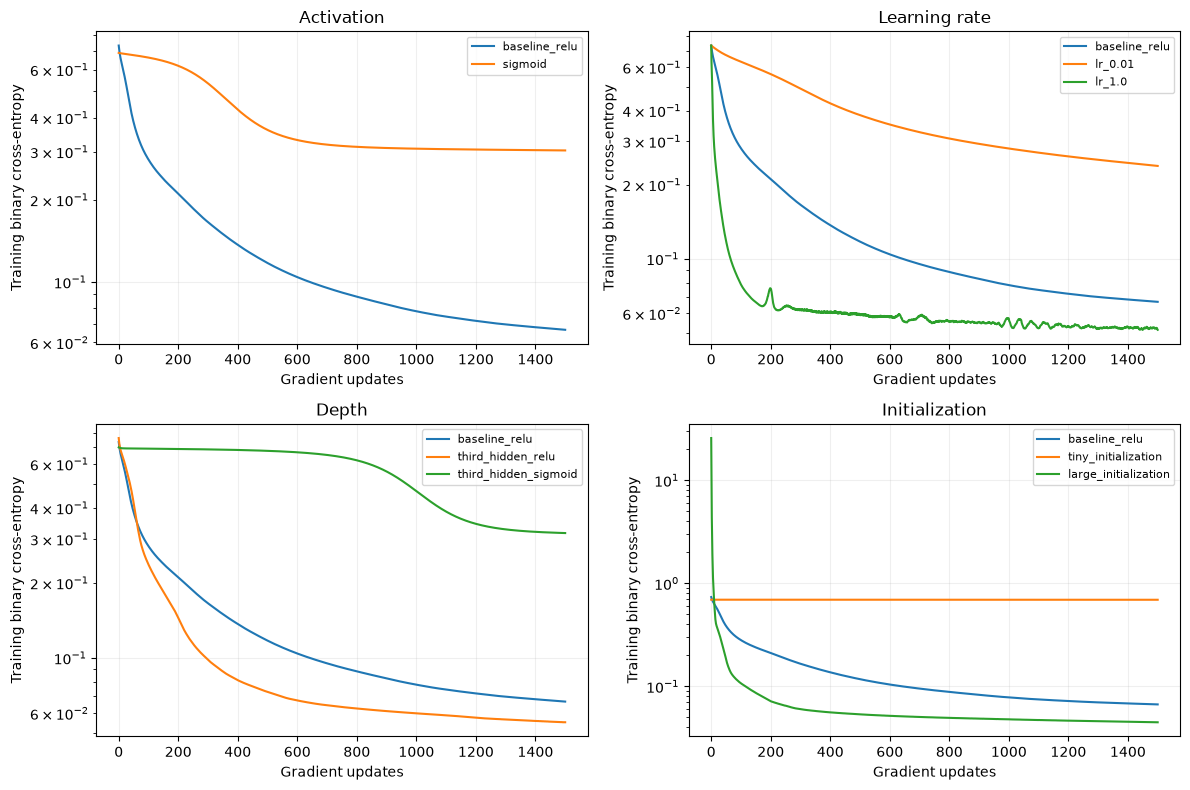

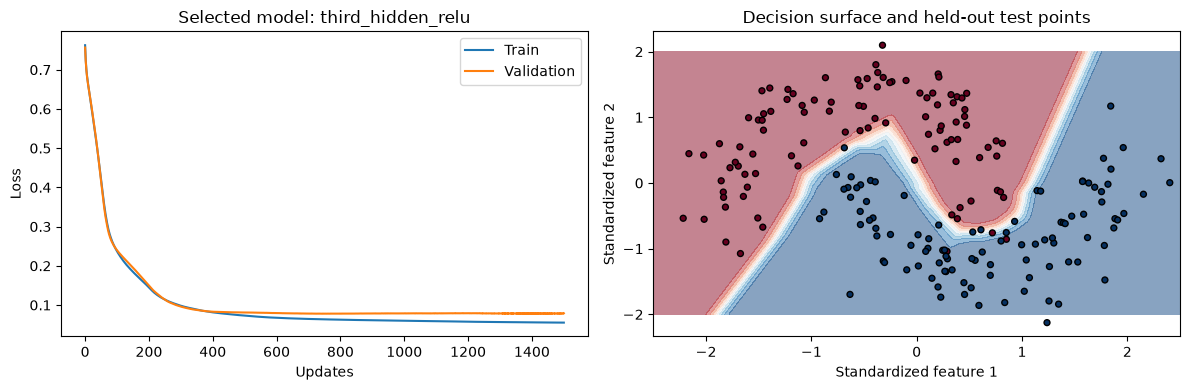

In [12]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
groups=[['baseline_relu','sigmoid'],['baseline_relu','lr_0.01','lr_1.0'],
        ['baseline_relu','third_hidden_relu','third_hidden_sigmoid'],
        ['baseline_relu','tiny_initialization','large_initialization']]
for ax,names,title in zip(axes.flat,groups,['Activation','Learning rate','Depth','Initialization']):
    for name in names:
        h=numpy_histories[name]; ax.plot(h.epoch,h.train_loss,label=name)
    ax.set(title=title,xlabel='Gradient updates',ylabel='Training binary cross-entropy',yscale='log')
    ax.legend(fontsize=8); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(OUTPUT/'challenge2_loss_experiments.png',dpi=160); plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,4))
h=numpy_histories[selected_name]
axes[0].plot(h.epoch,h.train_loss,label='Train'); axes[0].plot(h.epoch,h.val_loss,label='Validation')
axes[0].set(title=f'Selected model: {selected_name}',xlabel='Updates',ylabel='Loss'); axes[0].legend()
gx,gy=np.meshgrid(np.linspace(-2.5,2.5,180),np.linspace(-2,2,180))
prob=selected.forward(np.c_[gx.ravel(),gy.ravel()])[0][-1].reshape(gx.shape)
axes[1].contourf(gx,gy,prob,levels=np.linspace(0,1,11),cmap='RdBu',alpha=.5)
axes[1].scatter(mx_test[:,0],mx_test[:,1],c=my_test.ravel(),cmap='RdBu',edgecolors='k',s=18)
axes[1].set(title='Decision surface and held-out test points',xlabel='Standardized feature 1',ylabel='Standardized feature 2')
plt.tight_layout(); plt.savefig(OUTPUT/'challenge2_decision_surface.png',dpi=160); plt.show()


### Visualize forward activations and backward gradients
The following heatmaps show the baseline's layer activations for the same eight examples and the corresponding derivatives of loss with respect to preactivations (`dZ`). Read the top row left to right (forward) and the bottom row right to left (backward). The separate gradient-norm plot uses the same sample batch and initialization seed to compare initial gradient flow in deeper ReLU and sigmoid networks.


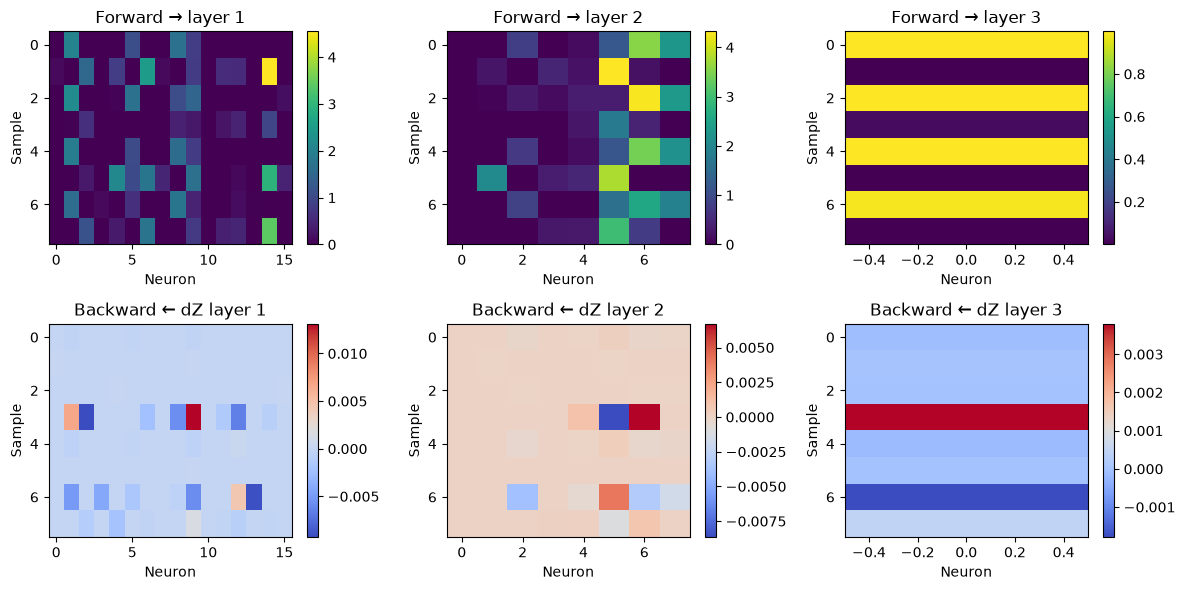

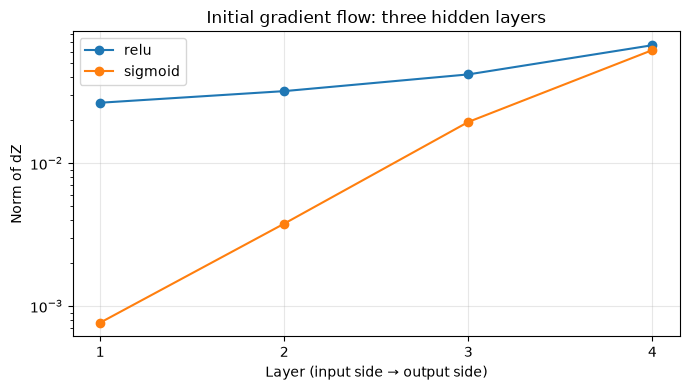

In [13]:
model=numpy_models['baseline_relu']
A,Z=model.forward(mx_train[:8]); dw,db,dz=model.backward(A,Z,my_train[:8])
fig,axes=plt.subplots(2,3,figsize=(12,6))
for i in range(3):
    im=axes[0,i].imshow(A[i+1],aspect='auto',cmap='viridis'); fig.colorbar(im,ax=axes[0,i])
    axes[0,i].set(title=f'Forward → layer {i+1}',xlabel='Neuron',ylabel='Sample')
    im=axes[1,i].imshow(dz[i],aspect='auto',cmap='coolwarm'); fig.colorbar(im,ax=axes[1,i])
    axes[1,i].set(title=f'Backward ← dZ layer {i+1}',xlabel='Neuron',ylabel='Sample')
plt.tight_layout(); plt.savefig(OUTPUT/'challenge2_flow.png',dpi=160); plt.show()

fig,ax=plt.subplots(figsize=(7,4))
for activation in ['relu','sigmoid']:
    probe=NumPyMLP([2,16,8,8,1],activation=activation,seed=SEED)
    pa,pz=probe.forward(mx_train[:64]); _,_,pdz=probe.backward(pa,pz,my_train[:64])
    norms=[np.linalg.norm(g) for g in pdz]
    ax.plot(range(1,5),norms,marker='o',label=activation)
ax.set(yscale='log',xticks=[1,2,3,4],xlabel='Layer (input side → output side)',
       ylabel='Norm of dZ',title='Initial gradient flow: three hidden layers')
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUTPUT/'challenge2_gradient_flow.png',dpi=160); plt.show()


### Interpreting gradient stability
Repeated multiplication by sigmoid derivatives (at most 0.25) and weight matrices can shrink early-layer gradients. Saturated sigmoid neurons have especially small derivatives. ReLU avoids saturation on its positive side but can have inactive neurons with zero gradients. Large weight matrices can amplify gradients; depth alone does not guarantee either vanishing or exploding gradients.

He initialization helps control activation scale for ReLU; smaller Xavier-style initialization is used for sigmoid. Tiny initialization can make learning slow, while large initialization can create excessive activations, saturation, and unstable updates. A high learning rate can also cause oscillations or divergence even without exploding gradients. Use the actual plots to distinguish these mechanisms; a larger initial gradient norm by itself is not proof of sustained exploding gradients.


In [14]:
# Reflection is generated from measured results; review its interpretation before submission.
r=numpy_results.set_index('experiment')
reflection=f"""The NumPy experiments showed that learning depended on activation choice, learning rate, network depth, and initialization. With two ReLU hidden layers, training loss changed from {r.loc['baseline_relu','initial_loss']:.3f} to {r.loc['baseline_relu','final_train_loss']:.3f}. The sigmoid variant reached validation accuracy of {r.loc['sigmoid','val_accuracy']:.1%}, compared with {r.loc['baseline_relu','val_accuracy']:.1%} for the ReLU baseline. These observations apply to this dataset and seed, rather than establishing a universal winner.

Changing the learning rate altered convergence: the smaller rate produced final training loss of {r.loc['lr_0.01','final_train_loss']:.3f}, while the larger rate produced {r.loc['lr_1.0','final_train_loss']:.3f}. Adding a third hidden layer changed both gradient flow and validation performance. Repeated multiplication during backpropagation explains why early layers can receive small gradients, especially with sigmoid derivatives. ReLU can preserve stronger gradients on positive inputs, although inactive neurons have zero derivatives.

Initialization also mattered: tiny and large initial weights produced validation losses of {r.loc['tiny_initialization','val_loss']:.3f} and {r.loc['large_initialization','val_loss']:.3f}, respectively. Appropriate scaling helps avoid weak signals and excessive activations. Validation loss guided model selection before the held-out test evaluation. Overall, the experiments demonstrated that greater depth alone does not ensure better learning, and gradient diagnostics help explain training behavior."""
assert 150<=len(reflection.split())<=200
display(Markdown('### Reflection ('+str(len(reflection.split()))+' words)\n\n'+reflection))
(OUTPUT/'reflection.md').write_text(reflection,encoding='utf-8')


### Reflection (175 words)

The NumPy experiments showed that learning depended on activation choice, learning rate, network depth, and initialization. With two ReLU hidden layers, training loss changed from 0.735 to 0.067. The sigmoid variant reached validation accuracy of 87.0%, compared with 98.0% for the ReLU baseline. These observations apply to this dataset and seed, rather than establishing a universal winner.

Changing the learning rate altered convergence: the smaller rate produced final training loss of 0.238, while the larger rate produced 0.051. Adding a third hidden layer changed both gradient flow and validation performance. Repeated multiplication during backpropagation explains why early layers can receive small gradients, especially with sigmoid derivatives. ReLU can preserve stronger gradients on positive inputs, although inactive neurons have zero derivatives.

Initialization also mattered: tiny and large initial weights produced validation losses of 0.692 and 0.127, respectively. Appropriate scaling helps avoid weak signals and excessive activations. Validation loss guided model selection before the held-out test evaluation. Overall, the experiments demonstrated that greater depth alone does not ensure better learning, and gradient diagnostics help explain training behavior.

1287

## Group review and references
Proposed review responsibilities (not a claim of completed individual contributions):

| Member | Review focus |
|---|---|
| Senay Teweldebrhan | Data preparation, Keras, and comparison interpretation |
| Ricardo | PyTorch implementation and experiment controls |
| Juan | TensorFlow custom loop, timing, and result tables |
| Zeyneb | NumPy derivation, gradient diagnostics, and reflection |

All four members should review both challenges and be able to explain forward propagation, loss, gradients, and validation. Replace this proposed allocation with actual contributions before submission if required.

**Primary course sources:** `MultiLayerPerceptrons_Workshop.ipynb`, Challenges 1 and 2, and `MultiLayeredPerceptrons.ipynb`, supplied course notes.

**Official implementation references:**
- [Keras model training APIs](https://keras.io/api/models/model_training_apis/)
- [PyTorch CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)
- [TensorFlow graph execution with tf.function](https://www.tensorflow.org/guide/function)

The optional framework-versus-NumPy extension is not included; all required Challenge 2 components are included. This notebook uses an explicit row-major notation equivalent to the worksheet's column-major formulas.
